# Q1: Multiple Linear Regression (from scratch)
Hypothesis h(x) = theta^T x, cost J = 1/(2m) [ sum(err^2) + lambda * sum_{j>=1} theta_j^2 ]
Gradients: j=0: (1/m) sum(err * x0);  j>=1: (1/m) sum(err * xj) + (lambda/m) theta_j
Update: theta_j := theta_j - alpha * dJ/dtheta_j  (vector form: theta -= alpha * grad)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
df = pd.read_csv("../ASSIGNMENT01/multiple_linear_regression_dataset.csv")
X, y = df.iloc[:, :-1].values.astype(float), df.iloc[:, -1].values.astype(float)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

In [3]:
mu, sigma = X_tr.mean(0), X_tr.std(0)
add_bias = lambda A: np.hstack([np.ones((len(A), 1)), A])
Xtr, Xte = add_bias((X_tr - mu) / sigma), add_bias((X_te - mu) / sigma)

In [4]:
def hypothesis(X, theta): return X @ theta

def cost(X, y, theta, lam):
    m = len(y)
    return (np.sum((hypothesis(X, theta) - y) ** 2) + lam * np.sum(theta[1:] ** 2)) / (2 * m)

def gradient_descent(X, y, alpha, lam, iters):
    m, theta, hist = len(y), np.zeros(X.shape[1]), []
    for _ in range(iters):
        grad = X.T @ (hypothesis(X, theta) - y) / m
        grad[1:] += (lam / m) * theta[1:]          # no regularization on theta_0
        theta -= alpha * grad
        hist.append(cost(X, y, theta, lam))
    return theta, hist

In [5]:
alpha, lam, iters = 0.1, 0.1, 500
theta, hist = gradient_descent(Xtr, y_tr, alpha, lam, iters)
print("Final theta:", theta, "\nFinal cost:", hist[-1])

Final theta: [42426.25        -846.64843329  8395.19312144] 
Final cost: 1094180.6515961543


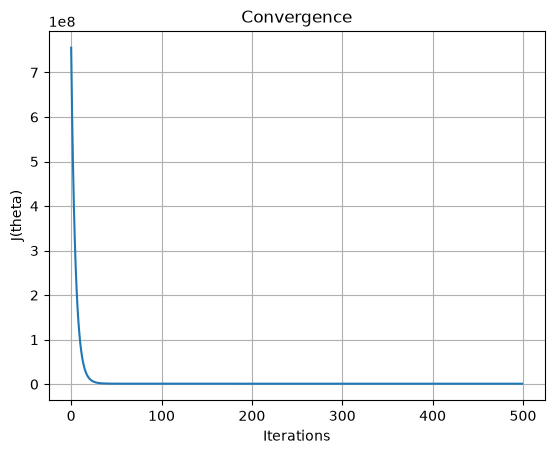

In [6]:
plt.plot(hist); plt.xlabel("Iterations"); plt.ylabel("J(theta)"); plt.title("Convergence"); plt.grid()
plt.savefig("results/q1_convergence.png", dpi=120); plt.show()

In [7]:
sk = LinearRegression().fit(Xtr[:, 1:], y_tr)
mse_ours = mean_squared_error(y_te, hypothesis(Xte, theta))
mse_sk = mean_squared_error(y_te, sk.predict(Xte[:, 1:]))
print(f"MSE ours: {mse_ours:.1f} | MSE sklearn: {mse_sk:.1f}")
print("sklearn intercept/coef:", sk.intercept_, sk.coef_)

MSE ours: 772533.9 | MSE sklearn: 753796.8
sklearn intercept/coef: 42426.25 [-884.53894609 8465.28543013]


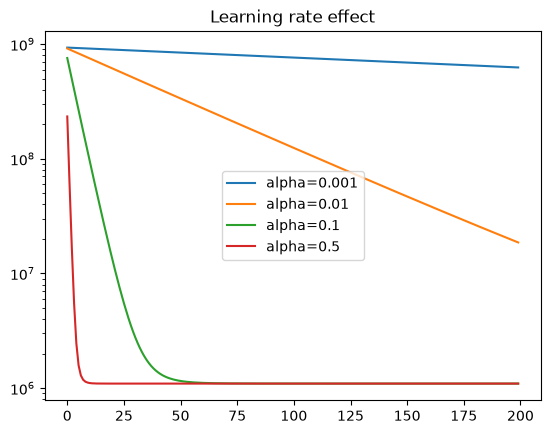

lambda=    0: test MSE=753796.8
lambda=  0.1: test MSE=772533.9
lambda=    1: test MSE=990779.0
lambda=   10: test MSE=6947101.8
lambda=  100: test MSE=52985223.9


In [8]:
for a in [0.001, 0.01, 0.1, 0.5]:
    plt.plot(gradient_descent(Xtr, y_tr, a, lam, 200)[1], label=f"alpha={a}")
plt.yscale("log"); plt.legend(); plt.title("Learning rate effect"); plt.show()
for l in [0, 0.1, 1, 10, 100]:
    t, _ = gradient_descent(Xtr, y_tr, alpha, l, iters)
    print(f"lambda={l:>5}: test MSE={mean_squared_error(y_te, hypothesis(Xte, t)):.1f}")

**Discussion (fill in from YOUR printed results):** small alpha converges slowly, too large diverges;
standardization lets one alpha work for all features; larger lambda shrinks theta (can under-fit),
lambda=0 matches sklearn. Dataset is tiny (20 rows), so the test MSE is noisy.